# Задача Wine dataset

В этой задаче нужно изучить данные о винах. Сделать визуализацию и выдвинуть гипотезы о вине.

In [8]:
# !pip install -q gdown
# !gdown https://drive.google.com/uc?id=1LsNeROfnVQb2ksdtwZvxrZREdy_Z-jta

In [9]:
import pandas as pd

In [10]:
data = pd.read_csv("winequality-red.csv")

In [11]:
data.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [12]:
data.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

In [13]:
data['alcohol']

0        9.4
1        9.8
2        9.8
3        9.8
4        9.4
        ... 
1594    10.5
1595    11.2
1596    11.0
1597    10.2
1598    11.0
Name: alcohol, Length: 1599, dtype: float64

**Задание 1.**

Поделите вина на три категории по содержанию алкоголя. Добавьте колонку `"category"` со значениями `"low alcohol"`, `"medium alcohol"`, `"high alcohol"` для относительного объемного содержания алкоголя `x<=10`, `10 < x <= 12`, `x > 12` соответственно.

In [14]:
def category(x):
    if x <= 10:
        return 'low alcohol'
    elif x <= 12:
        return 'medium alcohol'
    else:
        return 'high alcohol'

data['category'] = data['alcohol'].apply(category)

In [15]:
data['category']

0          low alcohol
1          low alcohol
2          low alcohol
3          low alcohol
4          low alcohol
             ...      
1594    medium alcohol
1595    medium alcohol
1596    medium alcohol
1597    medium alcohol
1598    medium alcohol
Name: category, Length: 1599, dtype: object

In [16]:
data[['residual sugar','category']].sample(5)

,residual sugar,category
615,2.3,low alcohol
327,4.5,medium alcohol
614,2.2,medium alcohol
202,1.5,low alcohol
780,2.0,low alcohol


In [17]:
data['category'].value_counts()

category
low alcohol       747
medium alcohol    711
high alcohol      141
Name: count, dtype: int64

**Задание 2.**

Для каждой категории посчитайте среднее и медиану содержания остаточного сахара (`"residual sugar"`). Сделайте pandas.DataFrame с индексами в виде категории содержания алкоголя и колнками в виде среднего и медианы.

In [18]:
data.groupby('category')['residual sugar'].agg(['mean', 'median']).sort_values(by='mean', ascending=False)

,mean,median
category,,
high alcohol,2.760993,2.3
medium alcohol,2.592264,2.2
low alcohol,2.445984,2.1


In [19]:
result = data.groupby('category')['residual sugar'].agg(['min', 'max'])
result['range'] = result['max'] - result['min']

result.sort_values(by='range', ascending=False)

,min,max,range
category,,,
low alcohol,1.2,15.5,14.3
medium alcohol,1.2,13.9,12.7
high alcohol,0.9,8.3,7.4


**Вопрос:**

Что можно сказать о распределении сахара по этим категориям? О распределении остаточного сахара в целом?

**Ответ:**

В целом видно, что распределение содержания остаточного сахара зависит от крепости алкоголя.

Если смотреть на значения средних и медианы, то распределение содержания остаточного сахара прямо пропорционально крепости алкоголя - чем выше содержания спирта, тем выше содержание остаточного сахара.

Но если посмотреть в целом распределение сахара, видно, что диапазон между минимальным содержанием сахара и его максимальным значением имеет гораздо большие размеры у слабого алкоголя, что может говорить о том, что у него распределение сахара более нестабильно по сравнению с более крепким.

**Задание 3.**

Постройте `boxplot` для остаточного сахара по категориям, полученным ранее на основании доли алкоголя.

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

In [21]:
palette = sns.color_palette("viridis", n_colors=3)[::-1]
#YOUR CODE GOES HERE

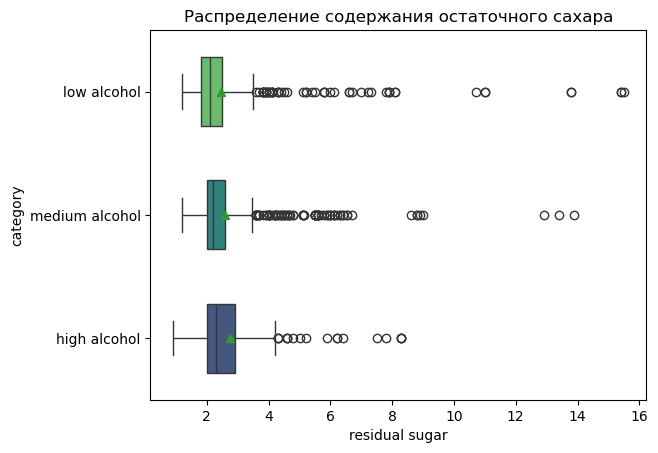

In [22]:
sns.boxplot(
    data=data,
    hue='category',
    x='residual sugar',
    y='category',
    palette=palette,
    gap=0.3,
    showmeans=True,
    )

plt.title('Распределение содержания остаточного сахара')
# plt.ylabel('category')
plt.show()

**Вопрос:**

Как соотнясятся оценки из предыдущего пункта и график сверху? Что лучше использовать для оценивания содержания сахара: медиану или среднее? Почему?

**Ответ:**

1. По оценкам средней и медианы видно, что их значения расходятся и среднее превышает значения медианы, из чего можно сделать вывод, что есть разбросы в сторону больших значений содержания сахара, что подтверждается графиком выше, где видны существенные выбросы в сторону больших величин, то есть вправо.

Я на графике добавила значение среднего. Что еще раз визуально подтверждает, что среднее сильно смещено вправо от медианы.

2. В данном случае для оценивания содержания сахара лучше использовать медиану, так как она более устойчива к выбросам.

**Задание 4.**

Проанализируйте обе выборки на предмет выбросов. Сколько их?

**Ответ:**

Так как на боксплоте видно, что выбросов много и значение среднего сильно смещено в сторону от медианы, то поиск выбросов логичнее считать не по правилу трех сигм, а по 1,5*IQR.

In [23]:
print("АНАЛИЗ ВЫБРОСОВ ПО КАТЕГОРИЯМ")
print("=" * 50)

categories = data['category'].unique()

outliers_total = 0

for category in categories:
    print(f"\nКатегория: {category}")
    print('-'*30)
    
    cat_alc = data[data['category'] == category]['residual sugar']
    
    Q1 = cat_alc.quantile(0.25)
    Q3 = cat_alc.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5*IQR
    upper_bound = Q3 + 1.5*IQR
    
    # Выбросы
    outliers = cat_alc[(cat_alc < lower_bound) | (cat_alc > upper_bound)]
    num_outliers = len(outliers)
    
    outliers_total += num_outliers
       
    print(f'Q1: {Q1}')
    print(f'Q3: {Q3}')
    print(f'IQR: {IQR.round(2)}')
    print(f"Минимальное значение: {cat_alc.min():.2f}")
    print(f"Максимальное значение: {cat_alc.max():.2f}")
    print(f'Выбросы находятся вне диапазона: [{lower_bound.round(2)}, {upper_bound.round(2)}]')
    print(f"Значения выбросов: {sorted(outliers.values)}")
    print(f"Количество записей: {len(cat_alc)}")
    print(f'Количество выбросов: {num_outliers}')
    
print()
print('='*50)
print(f"ВСЕГО ЗАПИСЕЙ: {len(data)}")
print(f'ВСЕГО ВЫБРОСОВ ПО ВСЕМ КАТЕГОРИЯМ: {outliers_total}')

АНАЛИЗ ВЫБРОСОВ ПО КАТЕГОРИЯМ

Категория: low alcohol
------------------------------
Q1: 1.8
Q3: 2.5
IQR: 0.7
Минимальное значение: 1.20
Максимальное значение: 15.50
Выбросы находятся вне диапазона: [0.75, 3.55]
Значения выбросов: [np.float64(3.6), np.float64(3.7), np.float64(3.8), np.float64(3.8), np.float64(3.8), np.float64(3.8), np.float64(3.8), np.float64(3.9), np.float64(3.9), np.float64(3.9), np.float64(3.9), np.float64(4.0), np.float64(4.0), np.float64(4.0), np.float64(4.1), np.float64(4.1), np.float64(4.1), np.float64(4.1), np.float64(4.3), np.float64(4.3), np.float64(4.3), np.float64(4.4), np.float64(4.5), np.float64(4.6), np.float64(5.1), np.float64(5.2), np.float64(5.2), np.float64(5.4), np.float64(5.5), np.float64(5.8), np.float64(5.8), np.float64(5.8), np.float64(6.0), np.float64(6.1), np.float64(6.6), np.float64(6.6), np.float64(6.7), np.float64(7.0), np.float64(7.2), np.float64(7.3), np.float64(7.8), np.float64(7.9), np.float64(7.9), np.float64(7.9), np.float64(8.1), np.

**Вывод:**

По результатам анализа видно, что количество выбросов достаточно большое в каждой выборке со смещением в сторону большего количества сахара. Конкретное число выбросов по каждой выборке напечатано выше.

**Задание 5.**

**1.** Постройте один `scatterplot` (используйте `seaborn`) для очень хороших и очень плохих вин (`quality == 3`, `quality == 8`) в зависимости от содержания алкоголя (`alcohol` **не** из предыдущего пункта, а из колонки исходного датасета) и от количества лимонной кислоты (`citric acid`). Используйте `palette=[palette[0]]+[palette[-1]]`.

In [24]:
# data.head()

In [25]:
quality_extr = data[(data['quality']==3) | (data['quality']==8)]
quality_extr.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,category
267,7.9,0.35,0.46,3.6,0.078,15.0,37.0,0.9973,3.35,0.86,12.8,8,high alcohol
278,10.3,0.32,0.45,6.4,0.073,5.0,13.0,0.9976,3.23,0.82,12.6,8,high alcohol
390,5.6,0.85,0.05,1.4,0.045,12.0,88.0,0.9924,3.56,0.82,12.9,8,high alcohol
440,12.6,0.31,0.72,2.2,0.072,6.0,29.0,0.9987,2.88,0.82,9.8,8,low alcohol
455,11.3,0.62,0.67,5.2,0.086,6.0,19.0,0.9988,3.22,0.69,13.4,8,high alcohol


In [26]:
sns.set_style('whitegrid')

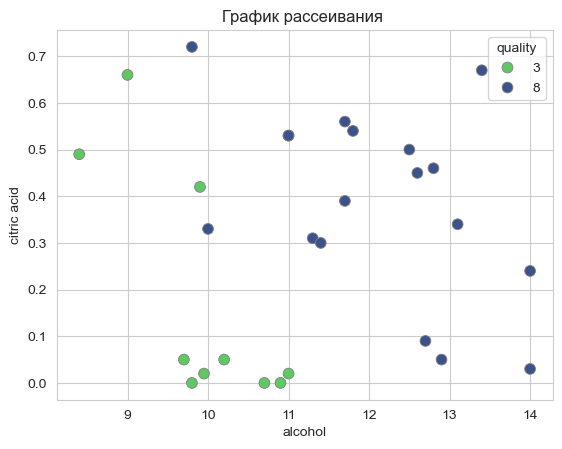

In [27]:
sns.scatterplot(
    x=quality_extr['alcohol'], 
    y=quality_extr['citric acid'], 
    data=quality_extr,
    hue=quality_extr['quality'],
    s=60,           
    palette=[palette[0]]+[palette[-1]],
    edgecolor='gray'  
)

plt.title('График рассеивания ')
plt.show()

#### **2.** Обе выборки из многомерного нормального распределения, предположите какие параметры у этого распреределения. Используйте `sps.multivariate_normal`.

In [28]:
import numpy as np
import scipy.stats as sps

In [29]:
bad_wine = data[data['quality']==3][['alcohol', 'citric acid']]
good_wine = data[data['quality']==8][['alcohol', 'citric acid']]

In [30]:
print(f"Хороших вин: {len(good_wine)}")
print(f"Плохих вин: {len(bad_wine)}")

print('\n'+'ПАРАМЕТРЫ У ПЛОХОГО ВИНА:')
print('='*50)

bad_wine['alcohol'].mean()
bad_wine['citric acid'].mean()
print(f'Координаты среднего: [{bad_wine['alcohol'].mean():.2f}, {bad_wine['citric acid'].mean():.2f}]')

print('Стандартное отклонение у плохого вина: ')
print(bad_wine['alcohol'].std())
print(bad_wine['citric acid'].std())
print('Дисперсия у плохого вина:')
print(bad_wine['alcohol'].var())
print(bad_wine['citric acid'].var())
print('Ковариационная матрица:')
print(np.cov(bad_wine['alcohol'], bad_wine['citric acid']))
# print('\n', bad_wine[['alcohol', 'citric acid']].cov())

print('\n'+'ПАРАМЕТРЫ У ХОРОШЕГО ВИНА:')
print('='*50)

good_wine['alcohol'].mean()
good_wine['citric acid'].mean()
print(f'Координаты среднего: [{good_wine['alcohol'].mean():.2f}, {good_wine['citric acid'].mean():.2f}]')

print('Стандартное отклонение: ')
print(good_wine['alcohol'].std())
print(good_wine['citric acid'].std())
print('Дисперсия у хорошего вина: ')
print(good_wine['alcohol'].var())
print(good_wine['citric acid'].var())
print('Ковариационная матрица:')
print(np.cov(good_wine['alcohol'], good_wine['citric acid']))
# print('\n', good_wine[['alcohol', 'citric acid']].cov())


Хороших вин: 18
Плохих вин: 10

ПАРАМЕТРЫ У ПЛОХОГО ВИНА:
Координаты среднего: [9.96, 0.17]
Стандартное отклонение у плохого вина: 
0.8180091007372036
0.250663563810583
Дисперсия у плохого вина:
0.6691388888888885
0.06283222222222223
Ковариационная матрица:
[[ 0.66913889 -0.15500556]
 [-0.15500556  0.06283222]]

ПАРАМЕТРЫ У ХОРОШЕГО ВИНА:
Координаты среднего: [12.09, 0.39]
Стандартное отклонение: 
1.224010871838598
0.19952558110763613
Дисперсия у хорошего вина: 
1.4982026143790848
0.03981045751633988
Ковариационная матрица:
[[ 1.49820261 -0.11240523]
 [-0.11240523  0.03981046]]


**3.** Нарисуйте график плотности с линиями контура и нанесите точки выборки. Используйте зеленый цвет для вина плохого качества (`get_density_cmap("Greens")` и `"g"` для точек) и синий для вина хорошего качества (`get_density_cmap("Blues")` и `"b"`). Используйте функции `plt.pcolormesh`, `plt.clabel` и `plt.scatter`. Не забудьте про `plt.xlabel`, `plt.ylabel` и `plt.legend`.

In [31]:
from matplotlib.colors import ListedColormap

def get_density_cmap(name):
    cmap =  plt.get_cmap(name)
    cmap_col = cmap(np.arange(cmap.N))
    cmap_col[:, -1] = np.linspace(0, 1, cmap.N)**2
    return ListedColormap(cmap_col)

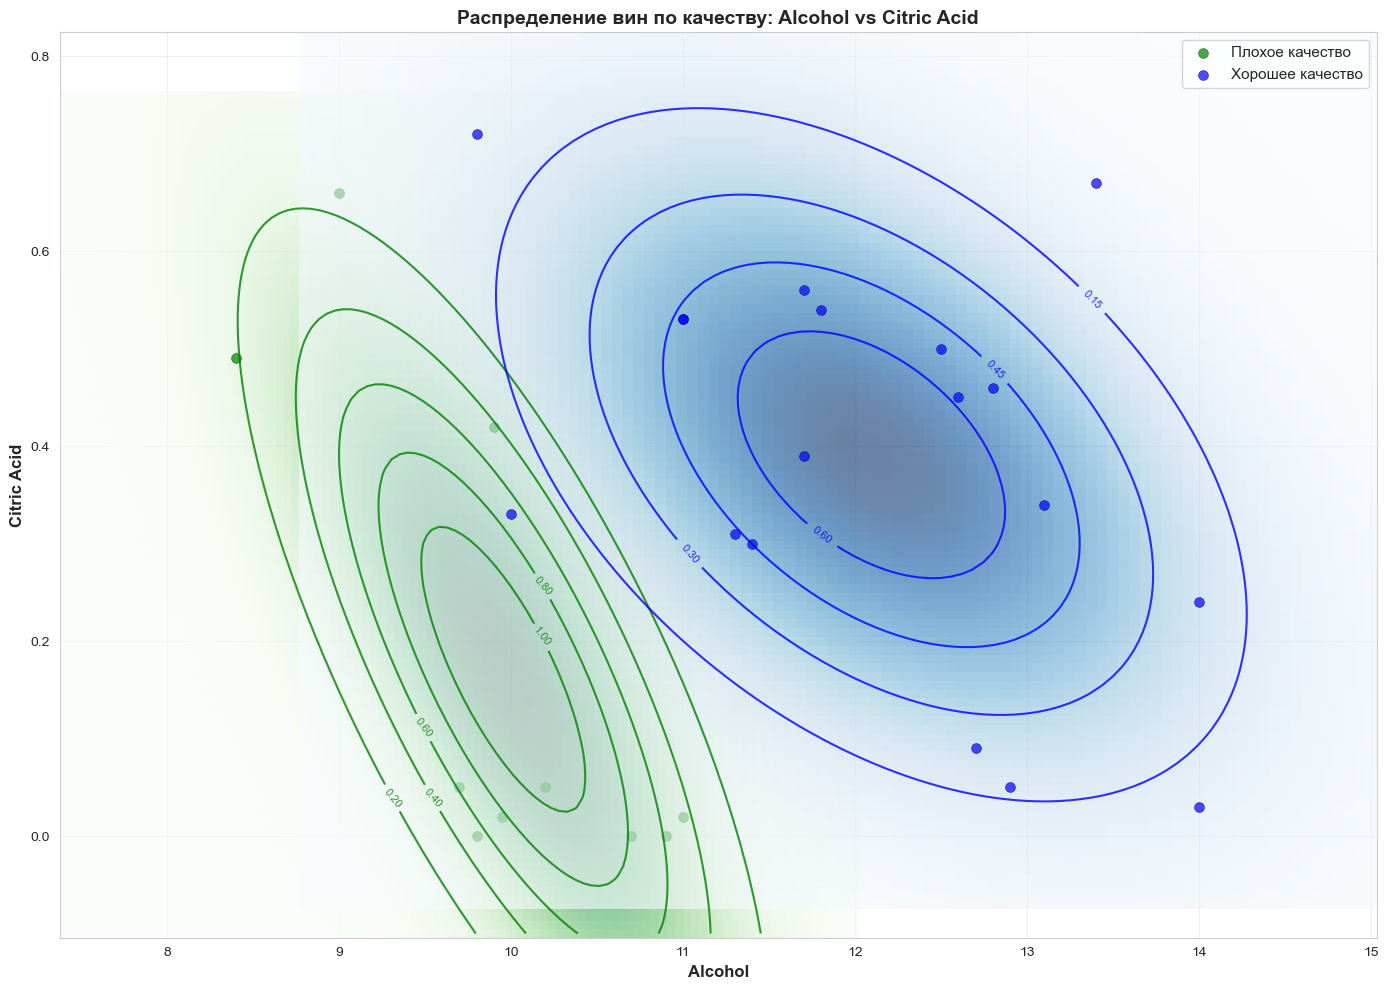

<Figure size 640x480 with 0 Axes>

In [32]:
plt.figure(figsize=(14, 10))

# для плохого вина

rv_bad = sps.multivariate_normal(
    mean=bad_wine[['alcohol', 'citric acid']].mean(), 
    cov=bad_wine[['alcohol', 'citric acid']].cov()
)

x_bad = np.linspace(bad_wine['alcohol'].min() - 1, bad_wine['alcohol'].max() + 1, 100)
y_bad = np.linspace(bad_wine['citric acid'].min() - 0.1, bad_wine['citric acid'].max() + 0.1, 100)
X_bad, Y_bad = np.meshgrid(x_bad, y_bad)
pos_bad = np.dstack((X_bad, Y_bad))

Z_bad = rv_bad.pdf(pos_bad)

plt.pcolormesh(X_bad, Y_bad, Z_bad, cmap=get_density_cmap("Greens"), shading='auto', alpha=0.6)

contour_bad = plt.contour(X_bad, Y_bad, Z_bad, levels=5, colors='green', linewidths=1.5, alpha=0.8)
plt.clabel(contour_bad, inline=True, fontsize=8, fmt='%.2f')

plt.scatter(bad_wine['alcohol'], bad_wine['citric acid'], 
            c='g', label='Плохое качество', alpha=0.7, 
            edgecolors='darkgreen', linewidth=0.5, s=50)

# для хорошего вина

rv_good = sps.multivariate_normal(
    mean=good_wine[['alcohol', 'citric acid']].mean(), 
    cov=good_wine[['alcohol', 'citric acid']].cov()
)

x_good = np.linspace(good_wine['alcohol'].min() - 1, good_wine['alcohol'].max() + 1, 100)
y_good = np.linspace(good_wine['citric acid'].min() - 0.1, good_wine['citric acid'].max() + 0.1, 100)
X_good, Y_good = np.meshgrid(x_good, y_good)
pos_good = np.dstack((X_good, Y_good))

Z_good = rv_good.pdf(pos_good)

plt.pcolormesh(X_good, Y_good, Z_good, cmap=get_density_cmap("Blues"), shading='auto', alpha=0.6)

contour_good = plt.contour(X_good, Y_good, Z_good, levels=5, colors='blue', linewidths=1.5, alpha=0.8)
plt.clabel(contour_good, inline=True, fontsize=8, fmt='%.2f')

plt.scatter(good_wine['alcohol'], good_wine['citric acid'], 
            c='b', label='Хорошее качество', alpha=0.7, 
            edgecolors='darkblue', linewidth=0.5, s=50)

plt.xlabel('Alcohol', fontsize=12, fontweight='bold')
plt.ylabel('Citric Acid', fontsize=12, fontweight='bold')
plt.title('Распределение вин по качеству: Alcohol vs Citric Acid', fontsize=14, fontweight='bold')
plt.legend(loc='best', fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig('alcohol_vs_citric_acid.png')  # сохраняем

**4.** Что можно сказать о вине, которому сомелье дали наивысший балл по сравнению с вином, которому дали наименьший балл, основываясь на график выше?

**Ответ:**



В целом Самелье отдали предпочтение более крепким винам со средней кислотностью во вкусе.

И наоборот, слабые вина с низкой кислотностью получили наименьший бал.